# Viajante con máscaras de bits (Held-Karp)

El problema del viajante busca la ruta más corta que sale de una ciudad, visita todas las demás una vez y vuelve. Probar las $(n-1)!$ rutas es inviable enseguida. Held-Karp guarda, para cada conjunto $S$ de ciudades visitadas (un entero cuyos bits marcan las ciudades) y cada ciudad final $j \in S$, el coste mínimo de salir de la ciudad 0, recorrer $S$ y acabar en $j$:

$$D[\{0\}][0] = 0, \qquad D[S][j] = \min_{i \in S \setminus \{j\}} \left( D[S \setminus \{j\}][i] + d(i, j) \right)$$

La ruta mínima es $\min_j D[\text{todas}][j] + d(j, 0)$. Hay $2^n \cdot n$ estados y cada uno mira $n$ anteriores: $O(2^n n^2)$ en tiempo y $O(2^n n)$ en memoria. Sigue siendo exponencial, pero mucho menos que $O(n!)$.

## 1. Fuerza bruta con permutaciones

Generar ciudades aleatorias en el plano, calcular la matriz de distancias euclídeas y probar con `itertools.permutations` todas las rutas que empiezan y acaban en la ciudad 0.

In [1]:
import math
import random
from itertools import permutations

def ciudades_aleatorias(n, semilla):
    rng = random.Random(semilla)
    puntos = [(rng.random(), rng.random()) for _ in range(n)]
    return puntos, [[math.dist(p, q) for q in puntos] for p in puntos]

def longitud(ruta, d):
    return sum(d[a][b] for a, b in zip(ruta, ruta[1:] + ruta[:1]))

def viajante_fuerza_bruta(d):
    n = len(d)
    mejor = min(permutations(range(1, n)), key=lambda resto: longitud([0, *resto], d))
    return longitud([0, *mejor], d), [0, *mejor]

puntos, d = ciudades_aleatorias(8, 1)
print(viajante_fuerza_bruta(d))

(3.1860709212864995, [0, 2, 4, 6, 1, 5, 3, 7])


## 2. Held-Karp con reconstrucción

Implementar la recurrencia recorriendo las máscaras en orden creciente (así $S \setminus \{j\}$, que es menor, ya está calculado) y guardar la ciudad anterior de cada estado para reconstruir la ruta. Comprobarlo contra fuerza bruta.

In [2]:
def held_karp(d):
    n = len(d)
    INF = math.inf
    D = [[INF] * n for _ in range(1 << n)]
    anterior = [[None] * n for _ in range(1 << n)]
    D[1][0] = 0
    for S in range(1, 1 << n):
        if not S & 1:
            continue  # todas las rutas salen de la ciudad 0
        for j in range(1, n):
            if not S >> j & 1:
                continue
            previo = S ^ (1 << j)
            for i in range(n):
                if previo >> i & 1 and D[previo][i] + d[i][j] < D[S][j]:
                    D[S][j], anterior[S][j] = D[previo][i] + d[i][j], i
    todas = (1 << n) - 1
    if n == 1:
        return 0, [0]
    final = min(range(1, n), key=lambda j: D[todas][j] + d[j][0])
    ruta, S, j = [], todas, final
    while j is not None:
        ruta.append(j)
        S, j = S ^ (1 << j), anterior[S][j]
    return D[todas][final] + d[final][0], ruta[::-1]

print(held_karp(d))

for semilla in range(100):
    n = random.Random(semilla).randint(1, 8)
    _, dist = ciudades_aleatorias(n, semilla)
    coste, ruta = held_karp(dist)
    assert math.isclose(coste, viajante_fuerza_bruta(dist)[0], abs_tol=1e-12)
    assert sorted(ruta) == list(range(n)) and ruta[0] == 0 and math.isclose(longitud(ruta, dist), coste, abs_tol=1e-12)

(3.186070921286499, [0, 7, 3, 5, 1, 6, 4, 2])


## 3. Comparar tiempos

Medir el tiempo de la fuerza bruta (hasta 10 ciudades) y de Held-Karp (hasta 16) y dibujarlos en escala logarítmica junto a las curvas $(n-1)!$ y $2^n n^2$ escaladas para que coincidan en el último punto medido.

n =  4: permutaciones   0.0000 s, Held-Karp   0.0000 s
n =  5: permutaciones   0.0000 s, Held-Karp   0.0000 s
n =  6: permutaciones   0.0001 s, Held-Karp   0.0003 s
n =  7: permutaciones   0.0006 s, Held-Karp   0.0002 s
n =  8: permutaciones   0.0049 s, Held-Karp   0.0004 s
n =  9: permutaciones   0.0434 s, Held-Karp   0.0010 s
n = 10: permutaciones   0.3864 s, Held-Karp   0.0022 s
n = 11: permutaciones          -, Held-Karp   0.0055 s
n = 12: permutaciones          -, Held-Karp   0.0131 s
n = 13: permutaciones          -, Held-Karp   0.0283 s
n = 14: permutaciones          -, Held-Karp   0.0659 s
n = 15: permutaciones          -, Held-Karp   0.1751 s
n = 16: permutaciones          -, Held-Karp   0.3382 s


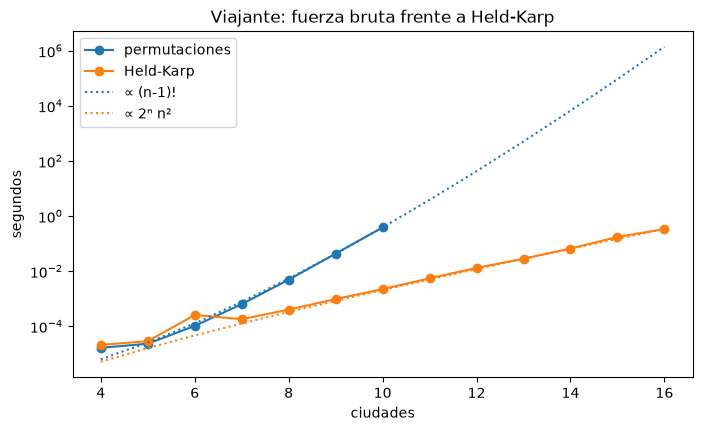

In [3]:
import time
import matplotlib.pyplot as plt

def mide(f, d):
    inicio = time.perf_counter()
    f(d)
    return time.perf_counter() - inicio

tamanos_fb, tamanos_hk = list(range(4, 11)), list(range(4, 17))
t_fb = [mide(viajante_fuerza_bruta, ciudades_aleatorias(n, n)[1]) for n in tamanos_fb]
t_hk = [mide(held_karp, ciudades_aleatorias(n, n)[1]) for n in tamanos_hk]
for n, a, b in zip(tamanos_hk, t_fb + [None] * 6, t_hk):
    print(f"n = {n:2}: permutaciones {f'{a:8.4f} s' if a is not None else '         -'}, Held-Karp {b:8.4f} s")

fig, eje = plt.subplots(figsize=(8, 4.5))
eje.plot(tamanos_fb, t_fb, "o-", label="permutaciones")
eje.plot(tamanos_hk, t_hk, "o-", label="Held-Karp")
escala_fb = t_fb[-1] / math.factorial(tamanos_fb[-1] - 1)
escala_hk = t_hk[-1] / (2 ** tamanos_hk[-1] * tamanos_hk[-1] ** 2)
eje.plot(tamanos_hk, [math.factorial(n - 1) * escala_fb for n in tamanos_hk], ":", color="C0", label="∝ (n-1)!")
eje.plot(tamanos_hk, [2 ** n * n ** 2 * escala_hk for n in tamanos_hk], ":", color="C1", label="∝ 2ⁿ n²")
eje.set(yscale="log", xlabel="ciudades", ylabel="segundos", title="Viajante: fuerza bruta frente a Held-Karp")
eje.legend()
plt.show()

## 4. Dibujar la ruta óptima

Con 13 ciudades, dibujar la ruta óptima de Held-Karp al lado de la que da la heurística voraz del vecino más cercano (ir siempre a la ciudad sin visitar más próxima), indicando la longitud de cada una.

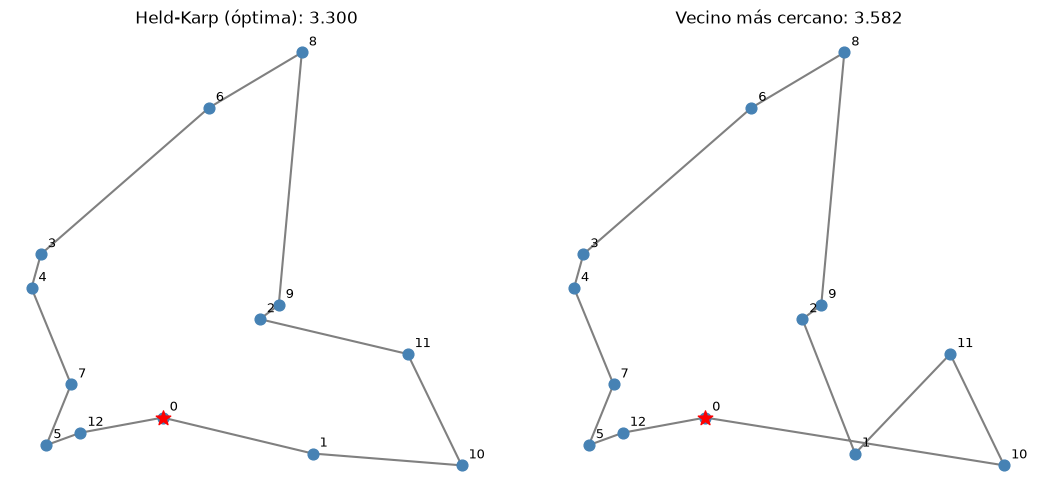

In [4]:
def vecino_mas_cercano(d):
    ruta, pendientes = [0], set(range(1, len(d)))
    while pendientes:
        siguiente = min(pendientes, key=lambda j: d[ruta[-1]][j])
        ruta.append(siguiente)
        pendientes.remove(siguiente)
    return longitud(ruta, d), ruta

puntos, d = ciudades_aleatorias(13, 7)
optima, voraz = held_karp(d), vecino_mas_cercano(d)
assert optima[0] <= voraz[0]

fig, ejes = plt.subplots(1, 2, figsize=(11, 5))
for eje, (coste, ruta), titulo in zip(ejes, (optima, voraz), ("Held-Karp (óptima)", "Vecino más cercano")):
    cerrada = ruta + ruta[:1]
    eje.plot([puntos[c][0] for c in cerrada], [puntos[c][1] for c in cerrada], "-", color="gray", zorder=1)
    eje.scatter(*zip(*puntos), color="steelblue", s=60, zorder=2)
    eje.scatter(*puntos[0], color="red", s=120, marker="*", zorder=3)
    for c, (x, y) in enumerate(puntos):
        eje.annotate(c, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=9)
    eje.set_title(f"{titulo}: {coste:.3f}")
    eje.set_aspect("equal")
    eje.axis("off")
plt.tight_layout()
plt.show()

## 5. Camino hamiltoniano sin volver

Si el viajante no tiene que volver al origen, la misma tabla sirve: el coste mínimo es $\min_j D[\text{todas}][j]$, sin sumar $d(j, 0)$. Escribir una versión que lo calcule y comprobarla contra fuerza bruta con distancias enteras no simétricas (por ejemplo, tiempos de viaje cuesta arriba y cuesta abajo).

In [5]:
def camino_minimo(d):
    n = len(d)
    D = [[math.inf] * n for _ in range(1 << n)]
    D[1][0] = 0
    for S in range(1, 1 << n, 2):
        for j in range(1, n):
            if S >> j & 1:
                previo = S ^ (1 << j)
                D[S][j] = min((D[previo][i] + d[i][j] for i in range(n) if previo >> i & 1), default=math.inf)
    return min(D[(1 << n) - 1])

def camino_fuerza_bruta(d):
    n = len(d)
    return min(sum(d[a][b] for a, b in zip((0, *resto), resto)) for resto in permutations(range(1, n)))

rng = random.Random(8)
for _ in range(100):
    n = rng.randint(1, 8)
    d = [[0 if i == j else rng.randint(1, 50) for j in range(n)] for i in range(n)]
    assert camino_minimo(d) == camino_fuerza_bruta(d)
print(camino_minimo([[0, 3, 9], [5, 0, 1], [2, 8, 0]]), camino_fuerza_bruta([[0, 3, 9], [5, 0, 1], [2, 8, 0]]))

4 4
